<a href="https://colab.research.google.com/github/gezahagnhailegnaw71-a11y/numerical_practice/blob/main/Fixed_Point_Iteration_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fixed-Point Iteration Method
**Numerical Analysis · Lab · Final version**

**Problem.** Solve $f(x)=0$.

**Idea.** Rewrite the equation in the form $x=g(x)$. A number $p$ with $g(p)=p$ is called a **fixed point** of $g$, and it is a root of the equation. Then start with a guess $x_0$ and repeat

$$x_{k+1}=g(x_k),\qquad k=0,1,2,\dots$$

until two answers are almost the same: $\lvert x_{k+1}-x_k\rvert<\text{tol}$.

**When does it work?** If $g$ is smooth and $\lvert g'(p)\rvert<1$, the iteration converges when $x_0$ is close to $p$. The smaller $\lvert g'(p)\rvert$ is, the faster it converges. If $\lvert g'(p)\rvert>1$ it **diverges**.

Unlike bisection and false position, this method needs **no interval**, only a starting guess $x_0$ and a good function $g$. But it can fail!

## Step 1: Import

In [ ]:
import math

## Step 2: Notation (quick reminder)
The **full notation guide** (math symbols, the meaning of `f`, all format codes, how to build a table) is in **Bisection_Method_Final.ipynb**. Here is a short reminder, and the notation that is **new** in this method.

| Format code | Meaning | Example |
|---|---|---|
| `f"{x:>14.8f}"` | right aligned, width 14, 8 decimals | `    1.36523001` |
| `f"{x:>12.2e}"` | scientific notation | `    3.14e+00` |
| `f"{n:>5d}"` | whole number, width 5 | `    7` |

### New in fixed-point iteration
| Notation | Meaning |
|---|---|
| `g(x)` | the function in $x=g(x)$ (a **new** function, different from $f$) |
| `x0` | the starting guess $x_0$ |
| `x_new = g(x)` | one iteration: $x_{k+1}=g(x_k)$ |
| `abs(x_new - x) < tol` | $\lvert x_{k+1}-x_k\rvert<\text{tol}$: two answers almost the same, so **stop** |
| `x = x_new` | the new value becomes the old value for the next step |
| `max_iter` | safety limit: stop after this many steps even if we have not converged |
| `try: ... except ...:` | try to compute; if an error happens (e.g. `math.sqrt(-1)`), do something else instead of crashing |
| `x**(1/3)` | cube root of $x$ (for $x>0$) |
| $\lvert g'(p)\rvert<1$ | the **convergence condition** |

## Step 3: Write the functions
### 3a. `print_table`: prints the steps as a table
We write the printing **once**, so every version of the method can use it.

In [ ]:
COLUMNS = ["step", "x_k", "g(x_k)", "|step|"]

def print_table(table):
    # header, line, one row for each step, line
    print(f"{'step':>5} {'x_k':>14} {'g(x_k)':>14} {'|step|':>12}")
    print("-" * 48)
    for row in table:
        print(f"{row[0]:>5d} {row[1]:>14.8f} {row[2]:>14.8f} {row[3]:>12.2e}")
    print("-" * 48)

### 3b. `fixed_point` with a `for` loop
The loop runs at most `max_iter` times and stops early with `break` when two answers are almost the same.

In [ ]:
def fixed_point(g, x0, tol=0.0001, max_iter=50, show=True):
    # g       : the function in x = g(x)
    # x0      : the starting guess
    # tol     : stop when two answers differ by less than tol
    # max_iter: safety limit on the number of steps
    # show    : True = print the table

    table = []                                    # one row for each step
    x = x0
    converged = False

    for step in range(1, max_iter + 1):           # at most max_iter steps
        try:
            x_new = g(x)                          # one iteration
        except (ValueError, OverflowError, ZeroDivisionError):
            if show:
                print(f"Stopped at step {step}: g(x) cannot be computed at x = {x}  (the iteration diverges)")
            return None, table

        table.append([step, x, x_new, abs(x_new - x)])     # save this row

        if abs(x_new - x) < tol:                  # two answers almost the same: stop
            converged = True
            x = x_new
            break
        x = x_new                                 # new value becomes the old value

    if show:
        print_table(table)
        if converged:
            print(f"Root = {x:.8f}   (found in {step} steps)\n")
        else:
            print(f"WARNING: no convergence after {max_iter} steps. Last value = {x:.8f}\n")

    return x, table

## Step 4: Example 1 — $\cos x - x = 0$
Rewrite as $x=\cos x$, so $g(x)=\cos x$. Start with $x_0=0.5$.

In [ ]:
def g1(x):
    return math.cos(x)

root, table = fixed_point(g1, 0.5)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     0.50000000     0.87758256     3.78e-01
    2     0.87758256     0.63901249     2.39e-01
    3     0.63901249     0.80268510     1.64e-01
    4     0.80268510     0.69477803     1.08e-01
    5     0.69477803     0.76819583     7.34e-02
    6     0.76819583     0.71916545     4.90e-02
    7     0.71916545     0.75235576     3.32e-02
    8     0.75235576     0.73008106     2.23e-02
    9     0.73008106     0.74512034     1.50e-02
   10     0.74512034     0.73500631     1.01e-02
   11     0.73500631     0.74182652     6.82e-03
   12     0.74182652     0.73723573     4.59e-03
   13     0.73723573     0.74032965     3.09e-03
   14     0.74032965     0.73824624     2.08e-03
   15     0.73824624     0.73964996     1.40e-03
   16     0.73964996     0.73870454     9.45e-04
   17     0.73870454     0.73934145     6.37e-04
   18     0.73934145     0.73891245     4.29e-04
   19     0.73891245

Look at the column `|step|`: it decreases slowly, by a factor of about $\lvert g'(p)\rvert=\lvert\sin p\rvert\approx0.67$ every step. That is **linear** convergence.

## Step 5: More examples
We only change `g(x)` and `x0`, then call `fixed_point` again.

In [ ]:
# Example 2:  e^(-x) - x = 0   ->   x = e^(-x)
def g2(x):
    return math.exp(-x)

root, table = fixed_point(g2, 0.5)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     0.50000000     0.60653066     1.07e-01
    2     0.60653066     0.54523921     6.13e-02
    3     0.54523921     0.57970309     3.45e-02
    4     0.57970309     0.56006463     1.96e-02
    5     0.56006463     0.57117215     1.11e-02
    6     0.57117215     0.56486295     6.31e-03
    7     0.56486295     0.56843805     3.58e-03
    8     0.56843805     0.56640945     2.03e-03
    9     0.56640945     0.56755963     1.15e-03
   10     0.56755963     0.56690721     6.52e-04
   11     0.56690721     0.56727720     3.70e-04
   12     0.56727720     0.56706735     2.10e-04
   13     0.56706735     0.56718636     1.19e-04
   14     0.56718636     0.56711886     6.75e-05
------------------------------------------------
Root = 0.56711886   (found in 14 steps)



In [ ]:
# Example 3:  x^3 - x - 1 = 0   ->   x = (x + 1)^(1/3)
def g3(x):
    return (x + 1) ** (1 / 3)

root, table = fixed_point(g3, 1.0)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     1.00000000     1.25992105     2.60e-01
    2     1.25992105     1.31229384     5.24e-02
    3     1.31229384     1.32235382     1.01e-02
    4     1.32235382     1.32426874     1.91e-03
    5     1.32426874     1.32463263     3.64e-04
    6     1.32463263     1.32470175     6.91e-05
------------------------------------------------
Root = 1.32470175   (found in 6 steps)



In [ ]:
# Example 4:  x^3 + 4x^2 - 10 = 0   ->   x = sqrt(10 / (4 + x))
def g4(x):
    return math.sqrt(10 / (4 + x))

root, table = fixed_point(g4, 1.5)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     1.50000000     1.34839972     1.52e-01
    2     1.34839972     1.36737637     1.90e-02
    3     1.36737637     1.36495702     2.42e-03
    4     1.36495702     1.36526475     3.08e-04
    5     1.36526475     1.36522559     3.92e-05
------------------------------------------------
Root = 1.36522559   (found in 5 steps)



In [ ]:
# Example 5:  x^2 - 2 = 0   ->   x = (x + 2/x) / 2     (this g is very fast: |g'(p)| = 0)
def g5(x):
    return (x + 2 / x) / 2

root, table = fixed_point(g5, 1.0)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     1.00000000     1.50000000     5.00e-01
    2     1.50000000     1.41666667     8.33e-02
    3     1.41666667     1.41421569     2.45e-03
    4     1.41421569     1.41421356     2.12e-06
------------------------------------------------
Root = 1.41421356   (found in 4 steps)



## Step 6: When fixed-point iteration fails
The same equation can be rewritten in **many** ways. Some work, some do not.

**Example 6.** $x^2-2=0$ rewritten as $x=\dfrac{2}{x}$: it never converges. It jumps between 1 and 2 forever.

In [ ]:
def g6(x):
    return 2 / x

root, table = fixed_point(g6, 1.0, max_iter=8)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     1.00000000     2.00000000     1.00e+00
    2     2.00000000     1.00000000     1.00e+00
    3     1.00000000     2.00000000     1.00e+00
    4     2.00000000     1.00000000     1.00e+00
    5     1.00000000     2.00000000     1.00e+00
    6     2.00000000     1.00000000     1.00e+00
    7     1.00000000     2.00000000     1.00e+00
    8     2.00000000     1.00000000     1.00e+00
------------------------------------------------



**Example 7.** $x^3+4x^2-10=0$ rewritten as $x=x-x^3-4x^2+10$: the numbers grow without bound.

In [ ]:
def g7(x):
    return x - x**3 - 4*x**2 + 10

root, table = fixed_point(g7, 1.5, max_iter=12)

Stopped at step 8: g(x) cannot be computed at x = -2.082712908581025e+216  (the iteration diverges)


**Example 8.** $x^3+4x^2-10=0$ rewritten as $x=\sqrt{\dfrac{10}{x}-4x}$: the square root of a negative number appears. Python stops with a clear message instead of crashing.

In [ ]:
def g8(x):
    return math.sqrt(10 / x - 4 * x)

root, table = fixed_point(g8, 1.5)

Stopped at step 3: g(x) cannot be computed at x = 2.99690880578722  (the iteration diverges)


## Step 7: Animations — watch the iterations converge or diverge
Each frame adds **one** iteration to the cobweb picture:
go **vertically** from $x_k$ to the curve $y=g(x)$, then **horizontally** to the line $y=x$. That point is $x_{k+1}$.

- If the red path moves **toward** the crossing point of $y=g(x)$ and $y=x$, the iteration **converges**.
- If it moves **away**, it **diverges**. If it repeats the same square, it **cycles**.

Press ▶ under each animation.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 40           # allow bigger animations in the notebook

def animate_cobweb(g, x0, xmin, xmax, steps=10, title=""):
    # 1. compute the iterates x0, x1, x2, ... (stop if they leave the window or cannot be computed)
    xs_it = [x0]
    for _ in range(steps):
        try:
            x_new = g(xs_it[-1])
        except (ValueError, OverflowError, ZeroDivisionError):
            break
        xs_it.append(x_new)
        if not (xmin - 5 * (xmax - xmin) < x_new < xmax + 5 * (xmax - xmin)):
            break                                     # far outside: stop computing

    # 2. the curve y = g(x) and the line y = x
    grid = [xmin + (xmax - xmin) * i / 300 for i in range(301)]
    curve = []
    for x in grid:
        try:
            curve.append(g(x))
        except (ValueError, OverflowError, ZeroDivisionError):
            curve.append(float("nan"))

    fig, ax = plt.subplots(figsize=(6, 5))

    def draw(frame):                                  # draw the picture after `frame` iterations
        ax.clear()
        ax.plot(grid, curve, color="#1f77b4", lw=2, label="y = g(x)")
        ax.plot(grid, grid, "k--", lw=1, label="y = x")
        for k in range(frame):                        # one vertical + one horizontal segment per step
            x, y = xs_it[k], xs_it[k + 1]
            ax.plot([x, x], [x, y], color="red", lw=1.3)
            ax.plot([x, y], [y, y], color="red", lw=1.3)
        ax.plot(xs_it[frame], xs_it[frame], "o", color="red", ms=7)
        ax.set_xlim(xmin, xmax); ax.set_ylim(xmin, xmax); ax.set_aspect("equal")
        ax.grid(alpha=0.3); ax.legend(loc="upper left")
        ax.set_title(f"{title}\nstep {frame}:  x_{frame} = {xs_it[frame]:.6f}")

    anim = FuncAnimation(fig, draw, frames=len(xs_it), interval=800)
    plt.close(fig)                                    # show only the animation, not an extra picture
    return HTML(anim.to_jshtml(default_mode="once"))

### Converges: $x = \cos x$ ( $\lvert g'(p)\rvert \approx 0.67 < 1$ )
The path **spirals in**, because $g'(p)<0$.

In [ ]:
animate_cobweb(g1, 0.1, 0, 1.2, steps=14, title="g(x) = cos x  (converges)")

### Converges: $x^3 - x - 1 = 0$, $\;g(x) = (x+1)^{1/3}$ ( $\lvert g'(p)\rvert \approx 0.19$ )
The path goes **up a staircase** into the root, because $0<g'(p)<1$.

In [ ]:
animate_cobweb(g3, 0.1, 0, 2, steps=8, title="g(x) = (x + 1)^(1/3)  (converges)")

### Diverges: $x^3 - 3x + 1 = 0$, $\;g(x) = \dfrac{x^3+1}{3}$, near $p \approx 1.532$ ( $\lvert g'(p)\rvert \approx 2.35 > 1$ )
Starting very close to the root, the path **climbs away** from it.

In [ ]:
def g9(x):
    return (x**3 + 1) / 3

animate_cobweb(g9, 1.56, 1.2, 2.6, steps=6, title="g(x) = (x^3 + 1)/3  (diverges)")

### Diverges: $x^3 - 4 = 0$, $\;g(x) = \dfrac{4}{x^2}$, near $p \approx 1.587$ ( $\lvert g'(p)\rvert = 2 > 1$ )
The path **spirals out**, away from the root.

In [ ]:
def g10(x):
    return 4 / x**2

animate_cobweb(g10, 1.55, 1.0, 2.4, steps=6, title="g(x) = 4/x^2  (spirals out: diverges)")

### Cycles: $x = \dfrac{2}{x}$ ( $\lvert g'(p)\rvert = 1$ )
The path repeats the **same square** forever: 1, 2, 1, 2, ...

In [ ]:
animate_cobweb(g6, 1.0, 0.5, 2.5, steps=6, title="g(x) = 2/x  (cycles forever)")

**What to remember**

| $g'(p)$ | Picture | Result |
|---|---|---|
| $0 < g'(p) < 1$ | staircase **in** | converges |
| $-1 < g'(p) < 0$ | spiral **in** | converges |
| $g'(p) > 1$ | staircase **out** | diverges |
| $g'(p) < -1$ | spiral **out** | diverges |
| $g'(p) = -1$ | square / cycle | no convergence |

**Try it:** change `x0`, or use your own `g`, in a call like `animate_cobweb(g, x0, xmin, xmax, steps, title)`.

## Step 8: Which rewriting is good? Check $\lvert g'(p)\rvert$
We estimate the slope of $g$ at the root with $g'(p)\approx\dfrac{g(p+h)-g(p-h)}{2h}$ (a small $h$) and compare with what the iteration does.

In [ ]:
def slope(g, p, h=1e-6):
    return (g(p + h) - g(p - h)) / (2 * h)          # numerical derivative of g at p

p = 1.365230013414097                               # the root of x^3 + 4x^2 - 10 = 0

# five different rewritings of the SAME equation x^3 + 4x^2 - 10 = 0
rewritings = [
    ("x - x^3 - 4x^2 + 10", lambda x: x - x**3 - 4*x**2 + 10),
    ("sqrt(10/x - 4x)",     lambda x: math.sqrt(10 / x - 4 * x)),
    ("0.5 sqrt(10 - x^3)",  lambda x: 0.5 * math.sqrt(10 - x**3)),
    ("sqrt(10/(4 + x))",    lambda x: math.sqrt(10 / (4 + x))),
    ("x - (x^3+4x^2-10)/(3x^2+8x)", lambda x: x - (x**3 + 4*x**2 - 10) / (3*x**2 + 8*x)),
]

print(f"{'g(x)':<30} {"|g'(p)|":>12} {'result':>14} {'steps':>6}   comment")
print("-" * 82)
for name, g in rewritings:
    s = abs(slope(g, p))
    root, table = fixed_point(g, 1.5, tol=1e-8, max_iter=50, show=False)
    if root is None:
        result, steps, comment = "-", len(table), "diverges (error)"
    elif abs(root - p) < 1e-6:
        result, steps, comment = f"{root:.8f}", len(table), "converges"
    else:
        result, steps, comment = f"{root:.3g}", len(table), "does not converge"
    print(f"{name:<30} {s:>12.3f} {result:>14} {steps:>6d}   {comment}")

g(x)                                |g'(p)|         result  steps   comment
----------------------------------------------------------------------------------
x - x^3 - 4x^2 + 10                  15.513              -      7   diverges (error)
sqrt(10/x - 4x)                       3.430              -      2   diverges (error)
0.5 sqrt(10 - x^3)                    0.512     1.36523001     27   converges
sqrt(10/(4 + x))                      0.127     1.36523001     10   converges
x - (x^3+4x^2-10)/(3x^2+8x)           0.000     1.36523001      4   converges


**Rule.** $\lvert g'(p)\rvert<1$: converges (the smaller, the faster). $\lvert g'(p)\rvert>1$: diverges. The last rewriting has $g'(p)=0$ and converges in very few steps. It is **Newton's method**, the subject of the next lesson.

## Step 9 (optional): The table with pandas

In [ ]:
import pandas as pd

root, table = fixed_point(g1, 0.5, tol=1e-6, show=False)
pd.DataFrame(table, columns=COLUMNS).set_index("step")

,x_k,g(x_k),|step|
step,,,
1,0.500000,0.877583,3.775826e-01
2,0.877583,0.639012,2.385701e-01
3,0.639012,0.802685,1.636726e-01
4,0.802685,0.694778,1.079071e-01
5,0.694778,0.768196,7.341780e-02
6,0.768196,0.719165,4.903039e-02
7,0.719165,0.752356,3.319031e-02
8,0.752356,0.730081,2.227470e-02
9,0.730081,0.745120,1.503928e-02


## Step 10 (optional): The cobweb picture
Go up/down to the curve $y=g(x)$, then across to the line $y=x$, and repeat.

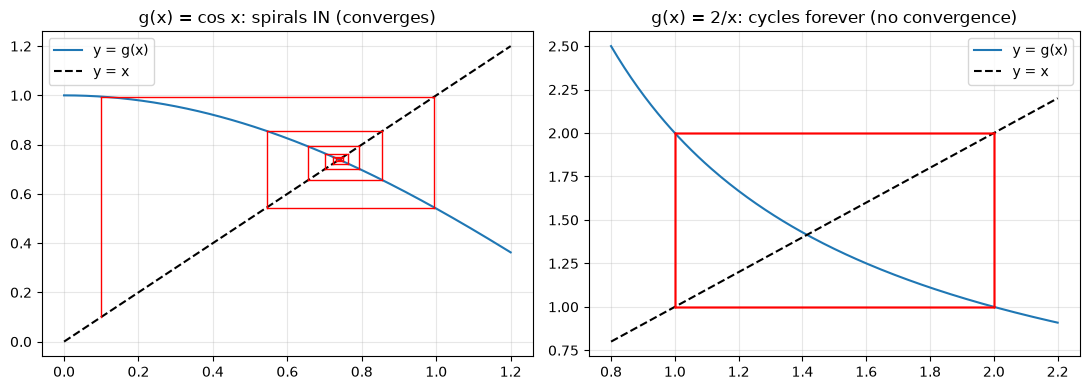

In [ ]:
import matplotlib.pyplot as plt

def cobweb(g, x0, xmin, xmax, steps=10, title=""):
    xs = [xmin + (xmax - xmin) * i / 200 for i in range(201)]
    plt.plot(xs, [g(x) for x in xs], label="y = g(x)")      # the curve
    plt.plot(xs, xs, "k--", label="y = x")                  # the line y = x
    x = x0
    for _ in range(steps):
        y = g(x)
        plt.plot([x, x], [x, y], "r", lw=1)                 # vertical segment to the curve
        plt.plot([x, y], [y, y], "r", lw=1)                 # horizontal segment to y = x
        x = y
    plt.title(title); plt.legend(); plt.grid(alpha=0.3)

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1); cobweb(g1, 0.1, 0, 1.2, 12, "g(x) = cos x: spirals IN (converges)")
plt.subplot(1, 2, 2); cobweb(g6, 1.0, 0.8, 2.2, 8, "g(x) = 2/x: cycles forever (no convergence)")
plt.tight_layout(); plt.show()

## Step 11 (optional): Error at each step

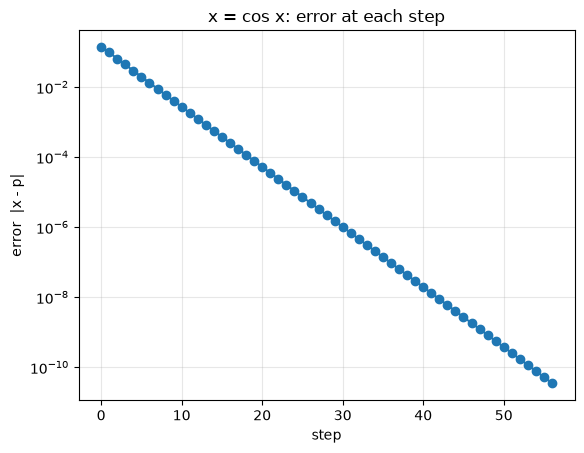

In [ ]:
p = 0.7390851332151607                      # the true root of cos x = x
root, table = fixed_point(g1, 0.5, tol=1e-10, max_iter=100, show=False)
errors = [abs(row[2] - p) for row in table]
plt.semilogy(errors, "o-")                  # log scale: a straight line means linear convergence
plt.xlabel("step"); plt.ylabel("error  |x - p|"); plt.grid(alpha=0.3)
plt.title("x = cos x: error at each step"); plt.show()

## Step 12: The same method with a `while` loop
A `for` loop runs at most `max_iter` times and leaves early with `break`.
A `while` loop repeats **while** a condition is true. Here: while the two last answers are still far apart **and** we have not reached `max_iter`.

To start the loop we set `diff = tol + 1` (a number bigger than `tol`), so the condition is true the first time.

In [ ]:
def fixed_point_while(g, x0, tol=0.0001, max_iter=50, show=True):
    # same inputs and outputs as fixed_point, but written with a while loop
    table = []                                    # one row for each step
    x = x0
    step = 0
    diff = tol + 1                                # bigger than tol, so the loop starts

    while diff >= tol and step < max_iter:        # repeat WHILE not accurate enough
        step = step + 1
        try:
            x_new = g(x)                          # one iteration
        except (ValueError, OverflowError, ZeroDivisionError):
            if show:
                print(f"Stopped at step {step}: g(x) cannot be computed at x = {x}  (the iteration diverges)")
            return None, table

        diff = abs(x_new - x)                     # change from the last answer
        table.append([step, x, x_new, diff])      # save this row
        x = x_new                                 # new value becomes the old value

    if show:
        print_table(table)
        if diff < tol:
            print(f"Root = {x:.8f}   (found in {step} steps)\n")
        else:
            print(f"WARNING: no convergence after {max_iter} steps. Last value = {x:.8f}\n")

    return x, table

Both versions give the **same** table and root:

In [ ]:
root, table = fixed_point_while(g1, 0.5)

 step            x_k         g(x_k)       |step|
------------------------------------------------
    1     0.50000000     0.87758256     3.78e-01
    2     0.87758256     0.63901249     2.39e-01
    3     0.63901249     0.80268510     1.64e-01
    4     0.80268510     0.69477803     1.08e-01
    5     0.69477803     0.76819583     7.34e-02
    6     0.76819583     0.71916545     4.90e-02
    7     0.71916545     0.75235576     3.32e-02
    8     0.75235576     0.73008106     2.23e-02
    9     0.73008106     0.74512034     1.50e-02
   10     0.74512034     0.73500631     1.01e-02
   11     0.73500631     0.74182652     6.82e-03
   12     0.74182652     0.73723573     4.59e-03
   13     0.73723573     0.74032965     3.09e-03
   14     0.74032965     0.73824624     2.08e-03
   15     0.73824624     0.73964996     1.40e-03
   16     0.73964996     0.73870454     9.45e-04
   17     0.73870454     0.73934145     6.37e-04
   18     0.73934145     0.73891245     4.29e-04
   19     0.73891245

In [ ]:
r1, t1 = fixed_point(g4, 1.5, show=False)          # for loop
r2, t2 = fixed_point_while(g4, 1.5, show=False)    # while loop
print("for   loop:", r1, " steps:", len(t1))
print("while loop:", r2, " steps:", len(t2))

for   loop: 1.365225594160525  steps: 5
while loop: 1.365225594160525  steps: 5


**`for` or `while`?**

| | `for` loop | `while` loop |
|---|---|---|
| Repeats | at most `max_iter` times | while a condition is true |
| Stops early with | `break` | the condition becomes false |
| Needs a start value | no | yes: `diff = tol + 1` so the loop starts |
| Danger | none: it always ends | if the condition never becomes false the loop never ends, so we also check `step < max_iter` |

## Summary
| | Fixed-point iteration |
|---|---|
| Formula | $x_{k+1}=g(x_k)$ |
| Needs | a rewriting $x=g(x)$ and a starting guess $x_0$ (no interval) |
| Stop when | $\lvert x_{k+1}-x_k\rvert<\text{tol}$ |
| Converges when | $\lvert g'(p)\rvert<1$ near the root, and $x_0$ is close to $p$ |
| Speed | linear (the error is multiplied by about $\lvert g'(p)\rvert$ each step) |
| Danger | a bad $g$ diverges or cycles |

## Your turn
Write your own `g(x)` and call `fixed_point`.
1. $x=e^{-x}$ with $x_0=1$ (answer about $0.5671$)
2. $x^3-2x-5=0$: use $g(x)=(2x+5)^{1/3}$, $x_0=2$ (answer about $2.0946$)
3. $x=\dfrac{1}{2}\left(x+\dfrac{3}{x}\right)$ with $x_0=1$ finds $\sqrt3$. How many steps does it need for `tol=1e-10`?
4. For $x^2-x-1=0$, try $g(x)=x^2-1$ and $g(x)=1+\dfrac1x$ with $x_0=1.5$. Which converges, and why? (Compute $\lvert g'(p)\rvert$ at $p=1.618$.)

In [ ]:
# write your code here